# Hip Replacement Surgery — Data Exploration and Analysis

This notebook explores the synthetic EPD (Electronic Patient Data) and patient-satisfaction
questionnaire data for hip replacement surgery patients covering **2016–2025**.

The dataset contains:
| Table | Description |
|---|---|
| `patient` | Demographic information per patient |
| `eoc` | Episodes of Care with intake / discharge dates |
| `eoc_treatment` | Primary and follow-up surgical treatments |
| `eoc_treatment_anesthesia` | Anesthesia records per EOC |
| `hip_treatment_position` | Surgical position per primary treatment |
| `patient_statistic` | Pre-operative BMI, smoking status and ASA score |
| `questionnaires/*.resp` | Post-operative patient-satisfaction scores (80 % of patients) |

---

## Setup — imports and data loading

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# ── Data directories ──────────────────────────────────────────────────────────
DATA_DIR  = Path('../data')
QUEST_DIR = DATA_DIR / 'questionnaires'

# ── Load EPD CSV files ────────────────────────────────────────────────────────
patient_df    = pd.read_csv(DATA_DIR / 'patient.csv', parse_dates=['dob'])
eoc_df        = pd.read_csv(DATA_DIR / 'eoc.csv',
                            parse_dates=['intake_date', 'discharge_date'])
treatment_df  = pd.read_csv(DATA_DIR / 'eoc_treatment.csv',
                            parse_dates=['eoc_time'])
anesthesia_df = pd.read_csv(DATA_DIR / 'eoc_treatment_anesthesia.csv',
                            parse_dates=['anesthesia_time'])
stat_df       = pd.read_csv(DATA_DIR / 'patient_statistic.csv',
                            parse_dates=['stat_ts'])

print(f'Patients:   {len(patient_df):,}')
print(f'EOCs:       {len(eoc_df):,}')
print(f'Treatments: {len(treatment_df):,}')

# ── Derived columns ───────────────────────────────────────────────────────────
eoc_df['year'] = eoc_df['intake_date'].dt.year

# Separate primary treatments from follow-up treatments
primary_df  = treatment_df[treatment_df['is_primary'] == 1].copy()
followup_df = treatment_df[treatment_df['is_primary'] == 0].copy()

# Flag each EOC: does it have at least one follow-up treatment?
eocs_with_fu = set(followup_df['eocid'].unique())
eoc_df['has_followup'] = eoc_df['eocid'].isin(eocs_with_fu)

n_fu  = eoc_df['has_followup'].sum()
pct_fu = eoc_df['has_followup'].mean()
print(f'\nEOCs with at least one follow-up treatment: {n_fu:,} ({pct_fu:.1%})')

Patients:   3,581
EOCs:       3,581
Treatments: 4,081

EOCs with at least one follow-up treatment: 464 (13.0%)


---
## 1. Number of Patients per Year

The bar chart below shows the total number of primary hip replacement surgeries per year.

Key observations:
- A **steady upward trend** is visible from 2016 to 2019, consistent with the ageing population.
- A sharp **COVID-19 dip** in 2020–2021 reflects the suspension of elective surgery.
- A **catch-up surge** in 2022–2023 as hospitals processed the accumulated backlog.
- Numbers return to the underlying trend in 2024–2025.

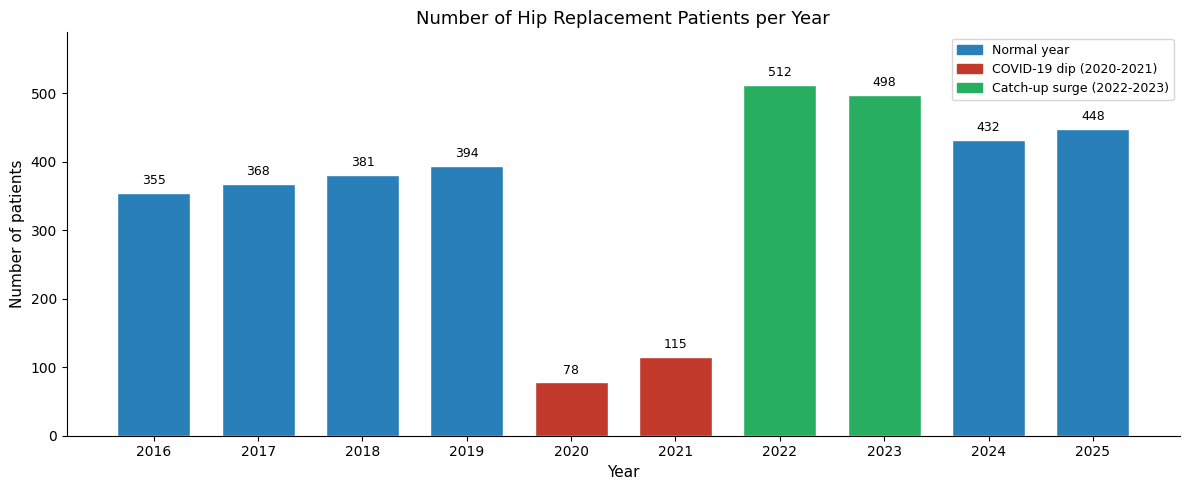

In [2]:
year_counts = eoc_df.groupby('year').size().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#c0392b' if y in (2020, 2021) else
          '#27ae60' if y in (2022, 2023) else
          '#2980b9' for y in year_counts.index]
bars = ax.bar(year_counts.index, year_counts.values,
              color=colors, edgecolor='white', width=0.7)

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Number of patients', fontsize=11)
ax.set_title('Number of Hip Replacement Patients per Year', fontsize=13)
ax.set_xticks(year_counts.index)
ax.set_ylim(0, year_counts.max() * 1.15)

# Annotate each bar with its count
for bar, val in zip(bars, year_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            str(val), ha='center', va='bottom', fontsize=9)

# Custom legend patches
import matplotlib.patches as mpatches
legend_handles = [
    mpatches.Patch(color='#2980b9', label='Normal year'),
    mpatches.Patch(color='#c0392b', label='COVID-19 dip (2020-2021)'),
    mpatches.Patch(color='#27ae60', label='Catch-up surge (2022-2023)'),
]
ax.legend(handles=legend_handles, fontsize=9)
plt.tight_layout()
plt.show()

---
## 2. Percentage of Patients with Follow-up Treatment per Year

Follow-up (re-intervention) treatments include arthrotomy, partial/complete revision,
and reposition procedures.

The chart illustrates a clear **downward trend** from ~17 % in 2016 to ~3 % in 2025,
reflecting improvements in surgical technique, implant design, and post-operative care.
A mild uptick in 2022–2023 coincides with the catch-up cohort of more complex deferred cases.

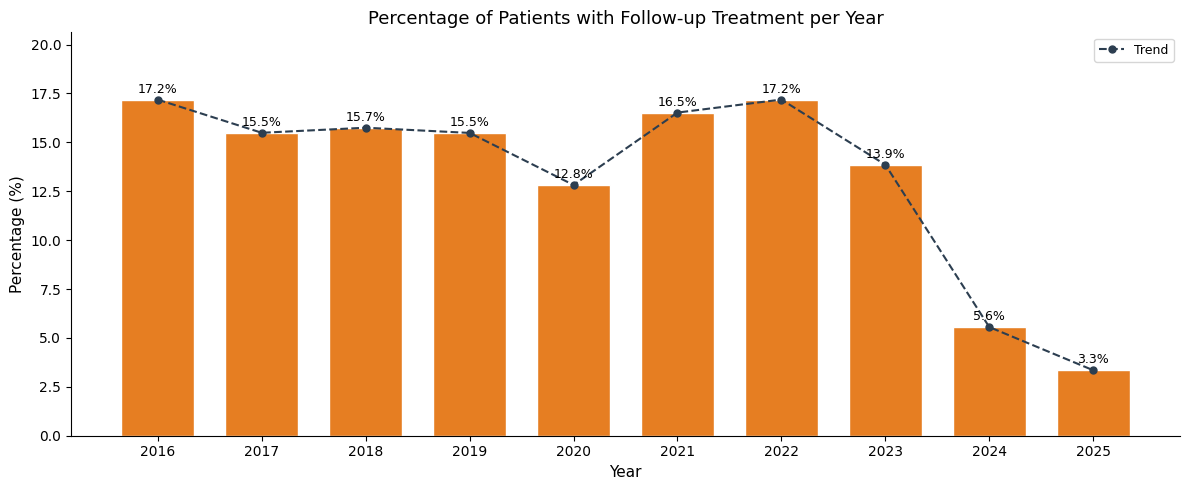

In [3]:
fu_by_year = (
    eoc_df.groupby('year')['has_followup']
    .agg(n_fu='sum', n_total='count')
    .assign(pct=lambda d: d['n_fu'] / d['n_total'] * 100)
)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(fu_by_year.index, fu_by_year['pct'],
              color='#e67e22', edgecolor='white', width=0.7)
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Percentage (%)', fontsize=11)
ax.set_title('Percentage of Patients with Follow-up Treatment per Year', fontsize=13)
ax.set_xticks(fu_by_year.index)
ax.set_ylim(0, fu_by_year['pct'].max() * 1.2)

for bar, val in zip(bars, fu_by_year['pct']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

# Overlay trend line
ax.plot(fu_by_year.index, fu_by_year['pct'], 'o--',
        color='#2c3e50', linewidth=1.5, markersize=5, label='Trend')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

---
## 3. Anesthesia Types for Primary Treatments Leading to Follow-up (by Year)

This stacked bar chart shows the **percentage of each anesthesia type** among the primary
hip replacement surgeries that ultimately required a follow-up intervention.

Spinal anesthesia is the most common method, consistent with clinical guidelines
for hip arthroplasty.  The relative distribution is stable across years, suggesting
that anesthesia choice does not change alongside the declining re-intervention rate.

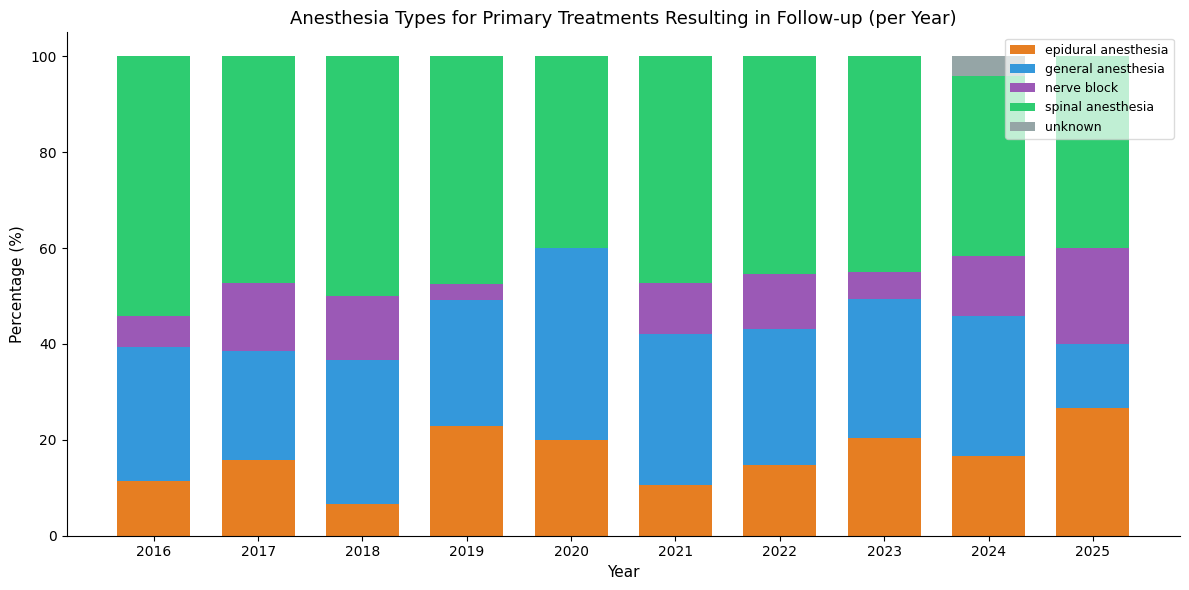

In [4]:
# Join primary treatments in EOCs-with-follow-up → anesthesia → year
primary_fu = primary_df[primary_df['eocid'].isin(eocs_with_fu)].copy()
primary_fu = primary_fu.merge(eoc_df[['eocid', 'year']], on='eocid')

# Each EOC has one anesthesia record for the primary treatment;
# the anesthesia table may have multiple rows per EOC (primary + follow-ups).
# We only want the anesthesia closest in time to the primary treatment,
# which is the one with the most recent time still before the primary eoc_time.
# For simplicity (and because primary anesthesia always precedes the treatment),
# we take the LAST anesthesia record per EOC (by time) that pre-dates the primary.
primary_fu_sorted = primary_fu.sort_values('eocid')
anesthesia_primary = (
    anesthesia_df
    .merge(primary_fu_sorted[['eocid', 'eoc_time', 'year']], on='eocid')
    .query('anesthesia_time < eoc_time')          # only pre-primary records
    .sort_values(['eocid', 'anesthesia_time'])
    .groupby('eocid')
    .last()                                        # latest pre-primary anesthesia
    .reset_index()
)

# Pivot to year × anesthesia_type counts, then convert to percentages
pivot = (
    anesthesia_primary
    .groupby(['year', 'anesthesia_type'])
    .size()
    .unstack(fill_value=0)
)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

type_colors = {
    'general anesthesia':  '#3498db',
    'spinal anesthesia':   '#2ecc71',
    'epidural anesthesia': '#e67e22',
    'nerve block':         '#9b59b6',
    'unknown':             '#95a5a6',
}

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(pivot_pct))
for col in pivot_pct.columns:
    ax.bar(pivot_pct.index, pivot_pct[col], bottom=bottom,
           label=col, color=type_colors.get(col, '#7f8c8d'), width=0.7)
    bottom += pivot_pct[col].values

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Percentage (%)', fontsize=11)
ax.set_title(
    'Anesthesia Types for Primary Treatments Resulting in Follow-up (per Year)',
    fontsize=13
)
ax.set_xticks(pivot_pct.index)
ax.set_ylim(0, 105)
ax.legend(loc='upper right', fontsize=9, framealpha=0.7)
plt.tight_layout()
plt.show()

---
## 4. ASA Score vs Follow-up Treatment Rate

The ASA (American Society of Anesthesiologists) physical status classification captures
the patient's overall health before surgery.

As expected, patients with **higher ASA scores** (more severe systemic conditions)
show a higher rate of requiring follow-up interventions after hip replacement surgery.
This suggests that pre-operative risk stratification is clinically meaningful and can
guide surgical planning and post-operative monitoring.

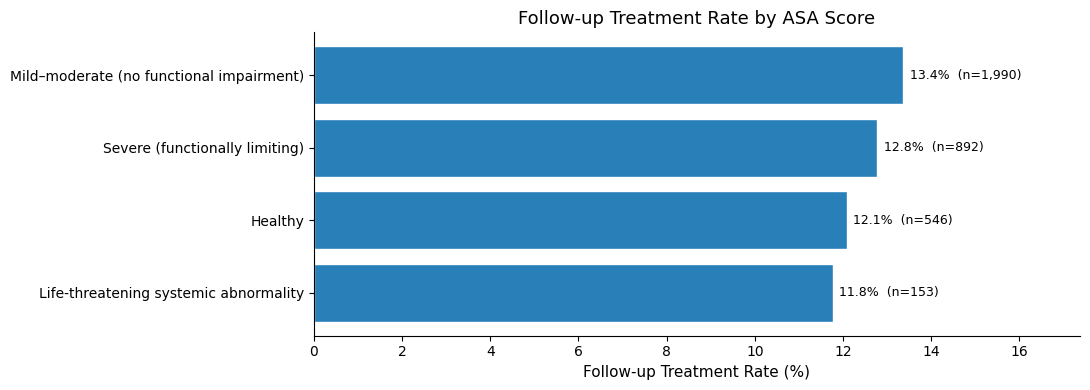

In [5]:
# Extract ASA scores (stid == 3) and merge with EOC follow-up flag
asa_df = (
    stat_df[stat_df['stid'] == 3][['pid', 'stvalue_string']]
    .rename(columns={'stvalue_string': 'asa'})
)
eoc_asa = eoc_df.merge(asa_df, on='pid')

asa_fu = (
    eoc_asa.groupby('asa')['has_followup']
    .agg(fu_pct=lambda x: x.mean() * 100, n='count')
    .reset_index()
    .sort_values('fu_pct', ascending=True)
)

# Shorten long ASA labels for display
label_map = {
    'healthy': 'Healthy',
    'mild to moderate systemic abnormality that does not result in functional impairment':
        'Mild–moderate (no functional impairment)',
    'Severe functionally limiting systemic abnormality':
        'Severe (functionally limiting)',
    'systemic abnormality that poses a constant life-threatening danger':
        'Life-threatening systemic abnormality',
}
asa_fu['asa_short'] = asa_fu['asa'].map(label_map).fillna(asa_fu['asa'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(
    range(len(asa_fu)), asa_fu['fu_pct'],
    color='#2980b9', edgecolor='white'
)
ax.set_yticks(range(len(asa_fu)))
ax.set_yticklabels(asa_fu['asa_short'], fontsize=10)
ax.set_xlabel('Follow-up Treatment Rate (%)', fontsize=11)
ax.set_title('Follow-up Treatment Rate by ASA Score', fontsize=13)

for bar, val, n in zip(bars, asa_fu['fu_pct'], asa_fu['n']):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%  (n={n:,})', va='center', fontsize=9)

ax.set_xlim(0, asa_fu['fu_pct'].max() * 1.3)
plt.tight_layout()
plt.show()

---
## 5. BMI Category vs Follow-up Treatment Rate

BMI (Body Mass Index) is a well-known predictor of surgical outcomes.
Patients are grouped into the standard WHO categories:
- **Underweight** (BMI < 18.5)
- **Normal weight** (18.5 – 24.9)
- **Overweight** (25.0 – 29.9)
- **Obese** (≥ 30)

The chart shows whether higher BMI categories are associated with a greater likelihood
of requiring a follow-up intervention after hip replacement surgery.

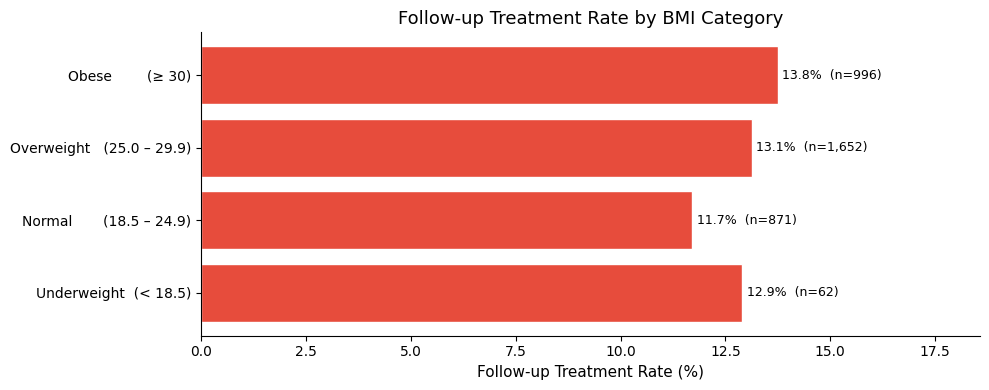

In [6]:
# Extract BMI values (stid == 1) and merge with EOC follow-up flag
bmi_df = (
    stat_df[stat_df['stid'] == 1][['pid', 'stvalue_int']]
    .rename(columns={'stvalue_int': 'bmi'})
)
eoc_bmi = eoc_df.merge(bmi_df, on='pid')

bmi_bins   = [0, 18.5, 25.0, 30.0, 100]
bmi_labels = [
    'Underweight  (< 18.5)',
    'Normal       (18.5 – 24.9)',
    'Overweight   (25.0 – 29.9)',
    'Obese        (≥ 30)',
]
eoc_bmi['bmi_cat'] = pd.cut(
    eoc_bmi['bmi'], bins=bmi_bins, labels=bmi_labels, right=False
)

bmi_fu = (
    eoc_bmi.groupby('bmi_cat', observed=True)['has_followup']
    .agg(fu_pct=lambda x: x.mean() * 100, n='count')
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(
    range(len(bmi_fu)), bmi_fu['fu_pct'],
    color='#e74c3c', edgecolor='white'
)
ax.set_yticks(range(len(bmi_fu)))
ax.set_yticklabels(bmi_fu['bmi_cat'].astype(str), fontsize=10)
ax.set_xlabel('Follow-up Treatment Rate (%)', fontsize=11)
ax.set_title('Follow-up Treatment Rate by BMI Category', fontsize=13)

for bar, val, n in zip(bars, bmi_fu['fu_pct'], bmi_fu['n']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%  (n={n:,})', va='center', fontsize=9)

ax.set_xlim(0, bmi_fu['fu_pct'].max() * 1.35)
plt.tight_layout()
plt.show()

---
## 6. Improvement in Daily Functioning: Patients With vs Without Follow-up Treatment

The questionnaire asks patients to score their **daily functioning** at 3 months and
at 12 months post-surgery (scale 0–8, where 8 = best).

The box plot below shows the **difference (12-month score − 3-month score)** grouped
by whether the patient required a follow-up intervention:

- A positive difference indicates improvement over the recovery period.
- Patients with follow-up treatments generally show a wider spread, reflecting the
  greater variability in recovery when complications require additional surgery.
- The dashed red line at zero marks no change in daily functioning.

Questionnaire responses loaded: 2,865


/var/folders/wj/f_j217vs1q7g2s1jh6cjy1vm0000gn/T/ipykernel_39150/604908417.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


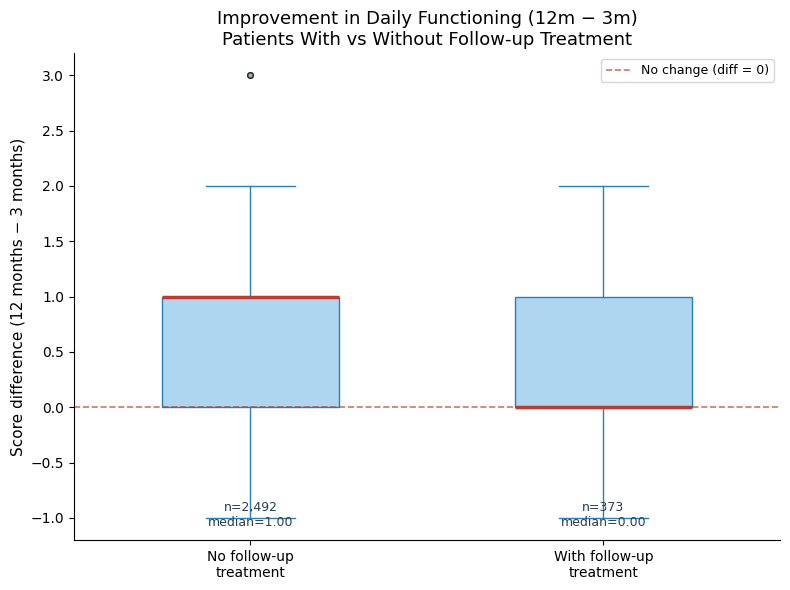

In [7]:
# ── Load questionnaire .resp files ───────────────────────────────────────────
records = []
for fname in os.listdir(QUEST_DIR):
    if not fname.endswith('.resp'):
        continue
    pid = int(fname.replace('.resp', ''))
    row = {'pid': pid}
    with open(QUEST_DIR / fname, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if ': ' in line:
                q, a = line.split(': ', 1)
                row[q] = float(a)
    records.append(row)

quest_df = pd.DataFrame(records)
print(f'Questionnaire responses loaded: {len(quest_df):,}')

# Compute the 12m – 3m difference in daily functioning
quest_df['diff_daily'] = (
    quest_df['Dagelijks functioneren na 12 maanden']
    - quest_df['Dagelijks functioneren na 3 maanden']
)

# Merge with the follow-up flag from the EOC table
quest_eoc = quest_df.merge(eoc_df[['pid', 'has_followup']], on='pid', how='left')
quest_eoc['group'] = quest_eoc['has_followup'].map(
    {True: 'With follow-up treatment', False: 'No follow-up treatment'}
)

# Build groups for box plot
group_no_fu = quest_eoc.loc[
    quest_eoc['group'] == 'No follow-up treatment', 'diff_daily'
].dropna()
group_fu = quest_eoc.loc[
    quest_eoc['group'] == 'With follow-up treatment', 'diff_daily'
].dropna()

fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot(
    [group_no_fu, group_fu],
    labels=['No follow-up\ntreatment', 'With follow-up\ntreatment'],
    patch_artist=True,
    widths=0.5,
    boxprops=dict(facecolor='#aed6f1', color='#2980b9'),
    medianprops=dict(color='#c0392b', linewidth=2.5),
    whiskerprops=dict(color='#2980b9'),
    capprops=dict(color='#2980b9'),
    flierprops=dict(marker='o', markerfacecolor='#95a5a6',
                    markersize=4, alpha=0.5),
)

ax.axhline(0, color='#c0392b', linestyle='--', linewidth=1.2, alpha=0.7,
           label='No change (diff = 0)')
ax.set_ylabel('Score difference (12 months − 3 months)', fontsize=11)
ax.set_title(
    'Improvement in Daily Functioning (12m − 3m)\n'
    'Patients With vs Without Follow-up Treatment',
    fontsize=13
)
ax.legend(fontsize=9)

# Annotate with median and sample size
for i, (grp, lbl) in enumerate(
    zip([group_no_fu, group_fu], ['No follow-up', 'With follow-up']),
    start=1,
):
    med = grp.median()
    ax.text(i, ax.get_ylim()[0] + 0.1,
            f'n={len(grp):,}\nmedian={med:.2f}',
            ha='center', va='bottom', fontsize=9, color='#2c3e50')

plt.tight_layout()
plt.show()